In [385]:
using Chakra
using DataFrames
using Pkg
using CSV
using Idyoms
push!(LOAD_PATH, "./src")
include("timit.jl")

Main.Timit

In [386]:
folder = joinpath("..", "data","output")

"..\\data\\output"

In [387]:
timit_h = Timit.TIMITHierarchy(folder)

Main.Timit.TIMITHierarchy("..\\data\\output", Main.Timit.SENTHierarchy[Main.Timit.SENTHierarchy(1×3 DataFrame
 Row │ onset_start  onset_stop  label                             
     │ Int64        Int64       SubStrin…                         
─────┼────────────────────────────────────────────────────────────
   1 │           0       48538  She,had,your,dark,suit,in,greasy…, Main.Timit.WORDHierarchy(11×3 DataFrame
 Row │ onset_start  onset_stop  label     
     │ Int64        Int64       DataStri… 
─────┼────────────────────────────────────
   1 │        2260        5320  she
   2 │        5320        8944  had
   3 │        8420        9733  your
   4 │        9733       14173  dark
   5 │       14173       18160  suit
   6 │       18160       20138  in
   7 │       20138       25939  greasy
   8 │       25939       31080  wash
   9 │       32080       37138  water
  10 │       37138       40175  all
  11 │       40175       45400  year, Main.Timit.PHNHierarchy(38×3 DataFrame
 Row │ o

In [388]:
print(size(collect(values(timit_h.sentence_map))))
print(size(collect(keys(timit_h.sentence_map))))
print(size(timit_h.sentences))

(1718,)(1718,)(1718,)

In [389]:
sents = collect(values(timit_h.sentence_map)) # plain ids for the sentence ids
sents = map((s) -> Timit.sentenceId(s), sents) # construct the ids of correct type
print(sents)

Main.Timit.SentenceId[Main.Timit.SentenceId(494), Main.Timit.SentenceId(1619), Main.Timit.SentenceId(1383), Main.Timit.SentenceId(501), Main.Timit.SentenceId(773), Main.Timit.SentenceId(1423), Main.Timit.SentenceId(1140), Main.Timit.SentenceId(1139), Main.Timit.SentenceId(410), Main.Timit.SentenceId(233), Main.Timit.SentenceId(804), Main.Timit.SentenceId(818), Main.Timit.SentenceId(1024), Main.Timit.SentenceId(542), Main.Timit.SentenceId(1055), Main.Timit.SentenceId(648), Main.Timit.SentenceId(305), Main.Timit.SentenceId(1289), Main.Timit.SentenceId(128), Main.Timit.SentenceId(321), Main.Timit.SentenceId(1178), Main.Timit.SentenceId(763), Main.Timit.SentenceId(1020), Main.Timit.SentenceId(213), Main.Timit.SentenceId(471), Main.Timit.SentenceId(1434), Main.Timit.SentenceId(1584), Main.Timit.SentenceId(136), Main.Timit.SentenceId(1172), Main.Timit.SentenceId(267), Main.Timit.SentenceId(1342), Main.Timit.SentenceId(165), Main.Timit.SentenceId(314), Main.Timit.SentenceId(1457), Main.Timit.

In [390]:
pts(Timit.SentenceId(773), Timit)

58-element Vector{Main.Timit.Id}:
 Main.Timit.PhonemeId(773, 0)
 Main.Timit.PhonemeId(773, 1)
 Main.Timit.PhonemeId(773, 2)
 Main.Timit.PhonemeId(773, 3)
 Main.Timit.PhonemeId(773, 4)
 Main.Timit.PhonemeId(773, 5)
 Main.Timit.PhonemeId(773, 6)
 Main.Timit.PhonemeId(773, 7)
 Main.Timit.PhonemeId(773, 8)
 Main.Timit.PhonemeId(773, 9)
 Main.Timit.PhonemeId(773, 10)
 Main.Timit.PhonemeId(773, 11)
 Main.Timit.PhonemeId(773, 12)
 ⋮
 Main.Timit.PhonemeId(773, 46)
 Main.Timit.PhonemeId(773, 47)
 Main.Timit.PhonemeId(773, 48)
 Main.Timit.PhonemeId(773, 49)
 Main.Timit.PhonemeId(773, 50)
 Main.Timit.PhonemeId(773, 51)
 Main.Timit.PhonemeId(773, 52)
 Main.Timit.PhonemeId(773, 53)
 Main.Timit.PhonemeId(773, 54)
 Main.Timit.PhonemeId(773, 55)
 Main.Timit.PhonemeId(773, 56)
 Main.Timit.PhonemeId(773, 57)

In [391]:
sequences = [sequence(pts(s, Timit), Timit) for s in sents]

1718-element Vector{Vector{Chakra.Constituent}}:
 [Main.Timit.Phoneme(Main.Timit.PhonemeId(494, 0), DataFrameRow
 Row │ onset_start  onset_stop  label     
     │ Int64        Int64       DataStri… 
─────┼────────────────────────────────────
   1 │           0        2750  h#), Main.Timit.Phoneme(Main.Timit.PhonemeId(494, 1), DataFrameRow
 Row │ onset_start  onset_stop  label     
     │ Int64        Int64       DataStri… 
─────┼────────────────────────────────────
   2 │        2750        4597  sh), Main.Timit.Phoneme(Main.Timit.PhonemeId(494, 2), DataFrameRow
 Row │ onset_start  onset_stop  label     
     │ Int64        Int64       DataStri… 
─────┼────────────────────────────────────
   3 │        4597        5681  iy), Main.Timit.Phoneme(Main.Timit.PhonemeId(494, 3), DataFrameRow
 Row │ onset_start  onset_stop  label     
     │ Int64        Int64       DataStri… 
─────┼────────────────────────────────────
   4 │        5681        6140  dcl), Main.Timit.Phoneme(Main.Timit.Phonem

In [392]:
PHONEME = vp(Timit.PhonemeAttribute())
phoneme_view = [View(seq, PHONEME, PHONEME) for seq in sequences]

1718-element Vector{View{String, String}}:
 View{String, String}(Union{Chakra.None, String}["h#", "sh", "iy", "dcl", "d", "aa", "l", "s", "ow", "r"  …  "d", "ay", "dcl", "d", "l", "ey", "dcl", "d", "axr", "h#"], Union{Chakra.None, String}["h#", "sh", "iy", "dcl", "d", "aa", "l", "s", "ow", "r"  …  "d", "ay", "dcl", "d", "l", "ey", "dcl", "d", "axr", "h#"], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  29, 30, 31, 32, 33, 34, 35, 36, 37, 38], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  29, 30, 31, 32, 33, 34, 35, 36, 37, 38], ["h#", "sh", "iy", "dcl", "d", "aa", "l", "s", "ow", "r"  …  "d", "ay", "dcl", "d", "l", "ey", "dcl", "d", "axr", "h#"], ["h#", "sh", "iy", "dcl", "d", "aa", "l", "s", "ow", "r"  …  "d", "ay", "dcl", "d", "l", "ey", "dcl", "d", "axr", "h#"])
 View{String, String}(Union{Chakra.None, String}["h#", "dh", "ey", "ix", "s", "ux", "m", "n", "ow", "bcl"  …  "v", "axr", "q", "eh", "nx", "axr", "hv", "ih", "axr", "h#"], Union{Chakra.None, String}["h#", "dh", "ey", "ix", "s", "ux", "m", "n", "ow

In [398]:
println(phoneme_view[1])

View{String, String}(Union{Chakra.None, String}["h#", "sh", "iy", "dcl", "d", "aa", "l", "s", "ow", "r", "ix", "m", "eh", "m", "bcl", "b", "er", "q", "ix", "f", "dh", "ix", "gcl", "g", "r", "ux", "m", "dcl", "d", "ay", "dcl", "d", "l", "ey", "dcl", "d", "axr", "h#"], Union{Chakra.None, String}["h#", "sh", "iy", "dcl", "d", "aa", "l", "s", "ow", "r", "ix", "m", "eh", "m", "bcl", "b", "er", "q", "ix", "f", "dh", "ix", "gcl", "g", "r", "ux", "m", "dcl", "d", "ay", "dcl", "d", "l", "ey", "dcl", "d", "axr", "h#"], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38], ["h#", "sh", "iy", "dcl", "d", "aa", "l", "s", "ow", "r", "ix", "m", "eh", "m", "bcl", "b", "er", "q", "ix", "f", "dh", "ix", "gcl", "g", "r", "ux", "m", "dcl", "d", "ay", "dcl", "d", "l", "ey", 

In [401]:
a = [
 "b","d","g","p","t","k",
 "bcl","dcl","gcl","pcl","tcl","kcl",
 "dx","q","jh","ch","s","sh","z","zh","f","th","v","dh",
 "m","n","ng","em","en","eng","nx",
 "l","r","w","y","hh","hv","el",
 "iy","ih","eh","ey","ae","aa","aw","ay","ah","ao","oy","ow","uh","uw","ux",
 "er","ax","ix","axr","ax-h",
 "pau","epi","h#",
 "1","2"
]
a = Set(a)
b = Interpolated()
e = A()
u = true
o = Bounded(5)

Bounded{5}()

In [ ]:
# takes 5 min
@time phoneme_stm       = Idyoms.ppm_stm(phoneme_view, a, b, e, u, o)
println("STM mean IC: ", Idyoms.mean_infcontent(phoneme_stm))

@time phoneme_ltm       = Idyoms.ppm_ltm(phoneme_view, a, b, e, u, o)
println("LTM mean IC: ", Idyoms.mean_infcontent(phoneme_ltm))

@time phoneme_ltm_plus  = Idyoms.ppm_ltm_plus(phoneme_view, a, b, e, u, o)
println("LTM+ mean IC: ", Idyoms.mean_infcontent(phoneme_ltm_plus))

@time phoneme_both      = Idyoms.ppm_both(phoneme_view, a, b, e, u, o)
println("BOTH mean IC: ", Idyoms.mean_infcontent(phoneme_both))

@time phoneme_both_plus = Idyoms.ppm_both_plus(phoneme_view, a, b, e, u, o)
println("BOTH+ mean IC: ", Idyoms.mean_infcontent(phoneme_both_plus))

phoneme_table = Idyoms.todataframe(phoneme_stm)
first(phoneme_table, 20) |> display

 17.431260 seconds (245.01 M allocations: 15.524 GiB, 41.03% gc time, 4.32% compilation time)
STM mean IC: 7.677745338897099
 86.689859 seconds (524.82 M allocations: 39.183 GiB, 21.93% gc time, 0.90% compilation time)
LTM mean IC: 4.657789452340131
 74.630020 seconds (530.24 M allocations: 40.234 GiB, 29.29% gc time, 0.06% compilation time)
LTM+ mean IC: 4.641577026364202
 73.199787 seconds (780.18 M allocations: 55.580 GiB, 21.87% gc time, 0.87% compilation time)
BOTH mean IC: 4.761096255451406
 82.048112 seconds (785.56 M allocations: 56.629 GiB, 27.30% gc time, 0.11% compilation time)
BOTH+ mean IC: 4.751747340827907


Row,SeqID,EventID,Symbol,Order,Prob,IC,H
,Int64,Int64,String,Int64,Float64,Float64,Float64
1,1,1,h#,-1,0.015873,5.97728,5.97728
2,1,2,sh,-1,0.00793651,6.97728,3.92966
3,1,3,iy,-1,0.00534759,7.54689,3.51942
4,1,4,dcl,-1,0.00406504,7.94251,3.44056
5,1,5,d,-1,0.00330033,8.24317,3.46727
6,1,6,aa,-1,0.0027933,8.48382,3.53391
7,1,7,l,-1,0.00243309,8.68299,3.61619
8,1,8,s,-1,0.0021645,8.85175,3.70383
9,1,9,ow,-1,0.00195695,8.99718,3.7921


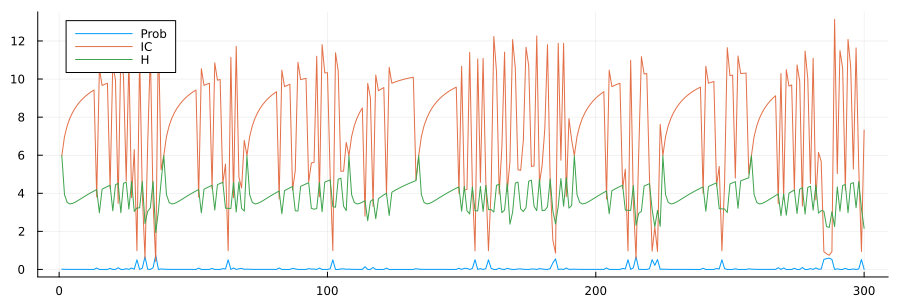

In [408]:
using Plots
N = min(300, nrow(phoneme_table))
plot(phoneme_table.Prob[1:N], label="Prob")
plot!(phoneme_table.IC[1:N], label="IC")
plot!(phoneme_table.H[1:N], label="H")
plot!(size=(900,300))